<a href="https://colab.research.google.com/github/ahmed-khaled04/bird_image_to_caption/blob/All-Models-notebook/20-epoch-EfficientNet.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# All classification models — Google Colab

Run these cells from top to bottom after selecting **Runtime → Change runtime type → GPU**. This notebook uses this project's `configs/transfer.yaml`, `src.experiment`, `src.transfer`, and `src.evaluation.report`. It trains the scratch CNN and the frozen and fine-tuned ResNet-18, ResNet-50, and EfficientNet-B0 models, then compares their saved best-epoch checkpoints on the validation split.

The notebook must be in the GitHub repo before opening it from GitHub in Colab. The cleaned dataset is rebuilt from the project's Hugging Face sources when a fresh Colab session starts. Checkpoints, run JSON files, tables, and figures are stored in Google Drive so completed runs survive a Colab disconnect. The seven full runs can take hours; rerun the training cell after a disconnect to skip completed runs. A small `LIMIT` is available for a pipeline check, but its scores are **not** reportable results.

The final test split is used only in the optional last cell, after you select one model using validation results.

In [14]:
# 1. Clone the project into Colab. An existing checkout is left untouched.
import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/ahmed-khaled04/bird_image_to_caption.git"
ROOT = Path("/content/bird_image_to_caption")
if not ROOT.exists():
    subprocess.run(["git", "clone", REPO_URL, str(ROOT)], check=True)
assert (ROOT / "src").is_dir() and (ROOT / "configs/transfer.yaml").is_file(), ROOT
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
print("Project:", ROOT)
subprocess.run(["git", "rev-parse", "--short", "HEAD"], check=True)

Project: /content/bird_image_to_caption


CompletedProcess(args=['git', 'rev-parse', '--short', 'HEAD'], returncode=0)

In [15]:
# 2. Install the project's dependencies. Colab already supplies torch and torchvision.
requirements = [line.strip() for line in (ROOT / "requirements.txt").read_text().splitlines()
                if line.strip() and not line.lstrip().startswith("#")
                and line.strip() not in {"torch", "torchvision"}]
subprocess.run([sys.executable, "-m", "pip", "install", "-q", *requirements], check=True)
import torch
print("Torch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Choose a GPU runtime before full training.")

Torch: 2.11.0+cu130
CUDA: True
GPU: Tesla T4


In [16]:
# 3. Mount Drive and make project/models point to persistent checkpoint storage.
from google.colab import drive

drive.mount("/content/drive")
DRIVE_ROOT = Path("/content/drive/MyDrive/bird_caption_generator")
DRIVE_MODELS = DRIVE_ROOT / "models"
DRIVE_MODELS.mkdir(parents=True, exist_ok=True)
model_link = ROOT / "models"
if model_link.is_symlink():
    assert model_link.resolve() == DRIVE_MODELS.resolve(), "models points to a different location"
elif model_link.exists():
    contents = list(model_link.iterdir())
    if any(item.name != ".gitkeep" for item in contents):
        raise RuntimeError("Project models/ contains files. Move them to Drive before linking it.")
    for item in contents:
        item.unlink()
    model_link.rmdir()
    model_link.symlink_to(DRIVE_MODELS, target_is_directory=True)
else:
    model_link.symlink_to(DRIVE_MODELS, target_is_directory=True)
print("Checkpoints:", model_link.resolve())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Checkpoints: /content/drive/MyDrive/bird_caption_generator/models


In [17]:
from datetime import datetime
from datasets import load_from_disk

DATA_DIR = ROOT / "data/processed"
splits = None

if DATA_DIR.exists():
    try:
        splits = load_from_disk(str(DATA_DIR))
        if not {"train", "validation", "test"}.issubset(splits):
            raise ValueError("A required split is missing")
    except (FileNotFoundError, ValueError, OSError) as error:
        backup = DATA_DIR.with_name(
            f"processed_incomplete_{datetime.now():%Y%m%d_%H%M%S}"
        )
        DATA_DIR.rename(backup)
        print(f"Incomplete data moved to {backup}: {error}")

if splits is None:
    subprocess.run(
        [sys.executable, "-m", "src.cli", "clean", "--no-plots"],
        check=True,
    )
    splits = load_from_disk(str(DATA_DIR))
    assert {"train", "validation", "test"}.issubset(splits)

print({name: len(split) for name, split in splits.items()})
del splits

Incomplete data moved to /content/bird_image_to_caption/data/processed_incomplete_20261101_110839: No such files: '/content/bird_image_to_caption/data/processed/test/dataset_info.json', nor '/content/bird_image_to_caption/data/processed/test/state.json' found. Expected to load a `Dataset` object but provided path is not a `Dataset`.
{'train': 5088, 'validation': 898, 'test': 5794}


## Choose the run settings

The seven model names and their hyperparameters come from `configs/transfer.yaml`. Keep `RUN_NAMES = None` for all seven. You may list a subset to split the work across Colab sessions. Full runs save under Drive `outputs/tables` and `outputs/figures`; a limited pipeline check uses a separate Drive folder so it cannot be mistaken for the full results. `NUM_WORKERS = 2` matches the project configuration.

In [23]:
import yaml
from src.transfer import run_configs

CONFIG = yaml.safe_load((ROOT / "configs/transfer.yaml").read_text())

RUN_NAMES = ["efficientnet_b0_finetune"]
LIMIT = None
NUM_WORKERS = 2

CONFIG["defaults"]["epochs"] = 20
CONFIG["defaults"]["num_workers"] = NUM_WORKERS

TABLE_DIR = DRIVE_ROOT / "outputs/tables_efficientnet_20"
FIG_DIR = DRIVE_ROOT / "outputs/figures_efficientnet_20"
RUNS_DIR = TABLE_DIR / "transfer_runs"
TENSORBOARD_DIR = DRIVE_ROOT / "outputs/tensorboard_efficientnet_20"

print("Runs:", [run["name"] for run in run_configs(CONFIG, RUN_NAMES)])
print("Epochs:", run_configs(CONFIG, RUN_NAMES)[0]["epochs"])
print("Tables:", TABLE_DIR)

Runs: ['efficientnet_b0_finetune']
Epochs: 20
Tables: /content/drive/MyDrive/bird_caption_generator/outputs/tables_efficientnet_20


In [24]:
# 6. Train using the same project functions as the CLI. Completed JSON runs are skipped.
import gc
from src.experiment import load_processed, train_run
from src.training.checkpoints import checkpoint_directory
from src.transfer import run_and_save

data = load_processed(DATA_DIR, LIMIT)
checkpoint_dir = checkpoint_directory()

def train_fn(run, **kwargs):
    return train_run(run, data, tensorboard_dir=TENSORBOARD_DIR, **kwargs)

for run in run_configs(CONFIG, RUN_NAMES):
    result = run_and_save(run, train_fn, RUNS_DIR, checkpoint_dir)
    print(run["name"], "best validation accuracy:", f"{result['best_val_accuracy']:.3%}",
          "at epoch", result["best_epoch"])
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

data: train 5088, validation 898, test 5794

=== efficientnet_b0_finetune: efficientnet_b0 fine-tune, 4,263,748 of 4,263,748 weights trainable, 20 epochs on cuda
TensorBoard: /content/drive/MyDrive/bird_caption_generator/outputs/tensorboard_efficientnet_20/efficientnet_b0_efficientnet_b0_finetune_20261101T132119211052Z_13634eab1f204fdfb63f93b653eabeae
epoch 1/20 | train loss 5.104 acc 0.046 | val loss 4.507 acc 0.229 | 58s
epoch 2/20 | train loss 4.006 acc 0.261 | val loss 3.125 acc 0.434 | 58s
epoch 3/20 | train loss 2.920 acc 0.451 | val loss 2.243 acc 0.555 | 59s
epoch 4/20 | train loss 2.179 acc 0.590 | val loss 1.704 acc 0.659 | 57s
epoch 5/20 | train loss 1.678 acc 0.680 | val loss 1.404 acc 0.697 | 57s
epoch 6/20 | train loss 1.340 acc 0.732 | val loss 1.183 acc 0.748 | 56s
epoch 7/20 | train loss 1.093 acc 0.781 | val loss 1.055 acc 0.762 | 57s
epoch 8/20 | train loss 0.904 acc 0.816 | val loss 0.943 acc 0.774 | 57s
epoch 9/20 | train loss 0.766 acc 0.842 | val loss 0.890 acc 0


=== transfer learning vs scratch (best validation accuracy)
run                efficientnet_b0_finetune
encoder                     efficientnet_b0
mode                              fine-tune
trainable_params_M                   4.2637
total_params_M                       4.2637
lr                                   0.0001
epochs                                   20
best_epoch                               19
best_val_accuracy                    0.8085
minutes                             18.9427
minutes_per_epoch                    0.9471
saved /content/drive/MyDrive/bird_caption_generator/outputs/figures_efficientnet_20/transfer_learning_curves.png
saved /content/drive/MyDrive/bird_caption_generator/outputs/figures_efficientnet_20/transfer_validation_scores.png


,encoder,mode,trainable_params_M,total_params_M,lr,epochs,best_epoch,best_val_accuracy,minutes,minutes_per_epoch
run,,,,,,,,,,
efficientnet_b0_finetune,efficientnet_b0,fine-tune,4.263748,4.263748,0.0001,20,19,0.808463,18.942683,0.947134


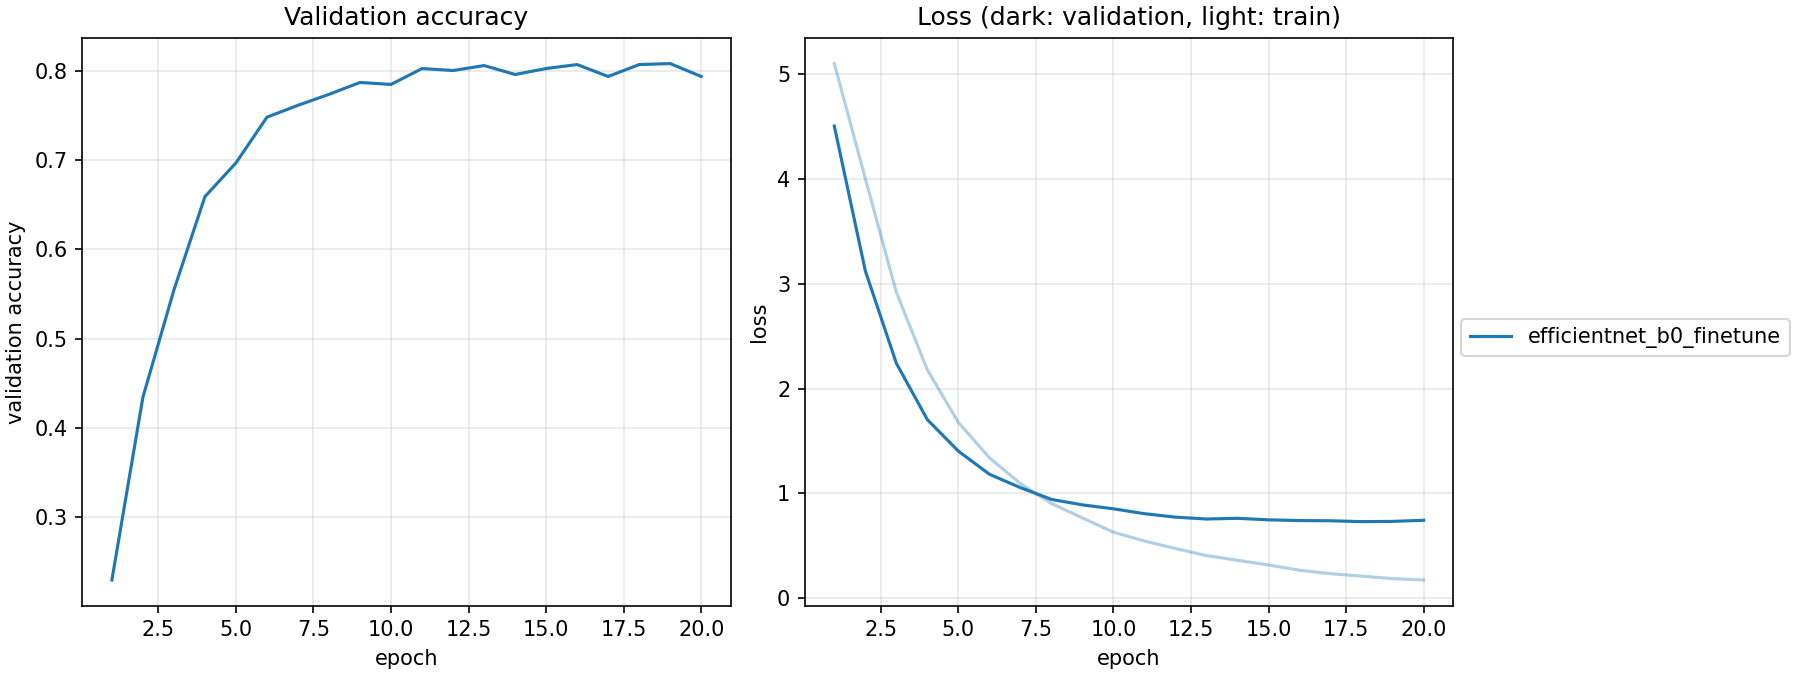

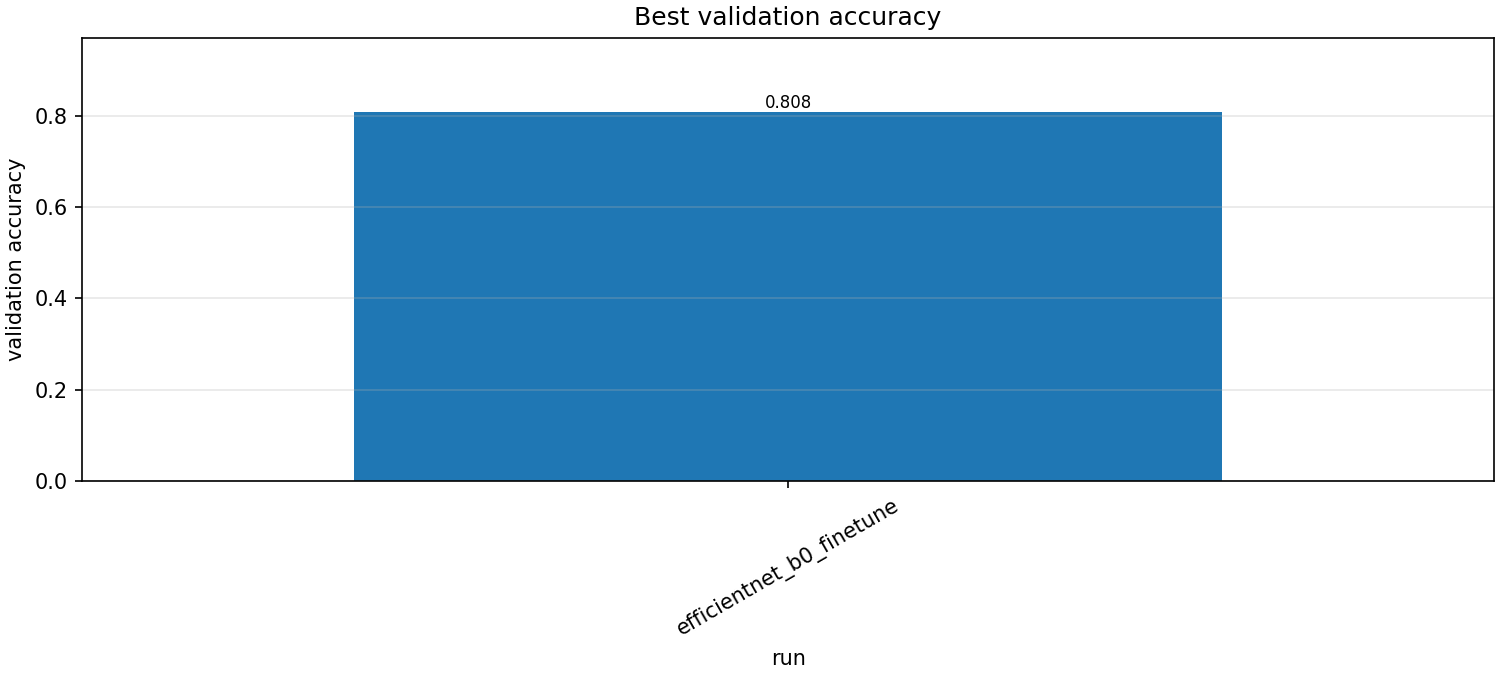

In [25]:
# 7. Save the project's comparison table and learning-curve figures.
from IPython.display import Image, display
from src.transfer import report

FIG_DIR.mkdir(parents=True, exist_ok=True)
comparison = report(CONFIG, TABLE_DIR, FIG_DIR, RUNS_DIR)
display(comparison.sort_values("best_val_accuracy", ascending=False))
display(Image(filename=str(FIG_DIR / "transfer_learning_curves.png")))
display(Image(filename=str(FIG_DIR / "transfer_validation_scores.png")))

In [26]:
# 8. Evaluate all seven saved best-epoch checkpoints on VALIDATION.
# This uses the project's accuracy, top-5, macro precision/recall/F1, confusion and per-class reports.
from src.evaluation.report import run_evaluation

EVAL_TABLE_DIR = TABLE_DIR / "evaluation"
EVAL_FIG_DIR = FIG_DIR / "evaluation"
selected_runs = [run["name"] for run in run_configs(CONFIG, RUN_NAMES)]
validation_table = run_evaluation(
    DATA_DIR, RUNS_DIR, checkpoint_dir, EVAL_TABLE_DIR, EVAL_FIG_DIR,
    selected_runs=selected_runs, test_run=None, num_workers=NUM_WORKERS, device="auto"
)
display(validation_table[["encoder", "mode", "accuracy", "top5_accuracy",
                          "precision_macro", "recall_macro", "f1_macro", "train_minutes"]])
print("Validation report:", EVAL_TABLE_DIR / "validation_comparison.csv")

saved /content/drive/MyDrive/bird_caption_generator/outputs/figures_efficientnet_20/evaluation/validation_efficientnet_b0_finetune_top_confusions.png
validated efficientnet_b0_finetune: accuracy 0.808, macro F1 0.796

=== validation comparison (all saved best-epoch checkpoints)
                                  encoder       mode  best_epoch  accuracy  top5_accuracy  precision_macro  recall_macro  f1_macro  train_minutes
run                                                                                                                                              
efficientnet_b0_finetune  efficientnet_b0  fine-tune          19     0.808          0.959            0.821         0.805     0.796         18.943


,encoder,mode,accuracy,top5_accuracy,precision_macro,recall_macro,f1_macro,train_minutes
run,,,,,,,,
efficientnet_b0_finetune,efficientnet_b0,fine-tune,0.808463,0.958797,0.8212,0.80525,0.796399,18.942683


Validation report: /content/drive/MyDrive/bird_caption_generator/outputs/tables_efficientnet_20/evaluation/validation_comparison.csv


## Final test: one model only

Choose the final model from the validation comparison above. Set its name below and run the cell once. Leave `FINAL_TEST_RUN = None` while comparing candidates. The test report is stored in a separate `final_test` folder so it does not replace the all-model validation comparison.

In [22]:
# 9. Optional final test after selecting ONE model on validation.
FINAL_TEST_RUN = None  # Example: "efficientnet_b0_finetune"
if FINAL_TEST_RUN is not None:
    assert FINAL_TEST_RUN in selected_runs, "Choose a name from selected_runs"
    final_table = run_evaluation(
        DATA_DIR, RUNS_DIR, checkpoint_dir,
        EVAL_TABLE_DIR / "final_test", EVAL_FIG_DIR / "final_test",
        selected_runs=[FINAL_TEST_RUN], test_run=FINAL_TEST_RUN,
        num_workers=NUM_WORKERS, device="auto"
    )
    print("Final test report:", EVAL_TABLE_DIR / "final_test/final_test_metrics.csv")
else:
    print("Test split untouched. Choose one model after reviewing validation results.")

Test split untouched. Choose one model after reviewing validation results.


## Saved evidence

Drive keeps the checkpoint files in `bird_caption_generator/models`, the per-run training JSON and comparison CSV in `bird_caption_generator/outputs/tables/transfer_runs` and `tables`, the validation metrics and confusion tables in `tables/evaluation`, the figures in `figures`, and TensorBoard logs in `tensorboard`. Copy reviewed results and images into the project for documentation when you are ready. Do not commit large checkpoint files unless your team has decided how to store them.